# 📊 Notebook 01 — Exploratory Data Analysis (EDA)
### Project: Customer Segmentation & Retention Analysis
**Dataset:** Telco Customer Churn &nbsp;|&nbsp; **Rows:** 7,043 &nbsp;|&nbsp; **Columns:** 21

---

## 🎯 Objectives of This Notebook

1. Understand the structure and quality of the dataset
2. Identify data quality issues (nulls, wrong dtypes, outliers)
3. Analyze churn distribution and class imbalance
4. Explore relationships between features and churn
5. Extract **5 key business findings** to guide modelling

---

> **⚠️ Dataset Note:**  
> Download the dataset from [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)  
> Place `WA_Fn-UseC_-Telco-Customer-Churn.csv` inside `../data/raw/`  
> If the file is not found, the notebook auto-generates a synthetic mirror dataset so all cells still run.

## 1. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

# ── Visual theme ──────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'font.family'    : 'DejaVu Sans',
    'figure.facecolor': '#F8F9FA',
    'axes.facecolor'  : '#F8F9FA',
})

# ── Consistent color palette ──────────────────────────────────
PALETTE   = {'No': '#4C9BE8', 'Yes': '#E8654C'}
COLOR_YES = '#E8654C'   # churn = warm red
COLOR_NO  = '#4C9BE8'   # no churn = calm blue
BG        = '#F8F9FA'

# ── Output directory ─────────────────────────────────────────
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('✅ Imports successful')

✅ Imports successful


## 2. Load Dataset

We look for the real Kaggle CSV first. If it's missing, a synthetic dataset with the **identical schema** is generated so every downstream cell runs without error.

In [2]:
DATA_PATH = '../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'

def load_or_synthesize(path):
    """Load real CSV or fall back to a synthetic mirror."""
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f'✅ Real dataset loaded from: {path}')
        return df, False

    print('⚠️  Real dataset not found — generating synthetic mirror ...')
    np.random.seed(42)
    n = 7043
    tenure  = np.random.randint(0, 72, n)
    monthly = np.round(np.random.uniform(18, 118, n), 2)
    total   = np.where(
        tenure == 0, '',
        np.round(monthly * tenure + np.random.normal(0, 10, n), 2).astype(str)
    )
    df = pd.DataFrame({
        'customerID'      : [f'CUST-{i:05d}' for i in range(n)],
        'gender'          : np.random.choice(['Male','Female'], n),
        'SeniorCitizen'   : np.random.choice([0, 1], n, p=[0.84, 0.16]),
        'Partner'         : np.random.choice(['Yes','No'], n),
        'Dependents'      : np.random.choice(['Yes','No'], n, p=[0.30, 0.70]),
        'tenure'          : tenure,
        'PhoneService'    : np.random.choice(['Yes','No'], n, p=[0.90, 0.10]),
        'MultipleLines'   : np.random.choice(['Yes','No','No phone service'], n),
        'InternetService' : np.random.choice(['DSL','Fiber optic','No'], n, p=[0.34, 0.44, 0.22]),
        'OnlineSecurity'  : np.random.choice(['Yes','No','No internet service'], n),
        'OnlineBackup'    : np.random.choice(['Yes','No','No internet service'], n),
        'DeviceProtection': np.random.choice(['Yes','No','No internet service'], n),
        'TechSupport'     : np.random.choice(['Yes','No','No internet service'], n),
        'StreamingTV'     : np.random.choice(['Yes','No','No internet service'], n),
        'StreamingMovies' : np.random.choice(['Yes','No','No internet service'], n),
        'Contract'        : np.random.choice(['Month-to-month','One year','Two year'],
                                             n, p=[0.55, 0.21, 0.24]),
        'PaperlessBilling': np.random.choice(['Yes','No'], n),
        'PaymentMethod'   : np.random.choice(
                              ['Electronic check','Mailed check',
                               'Bank transfer (automatic)','Credit card (automatic)'], n),
        'MonthlyCharges'  : monthly,
        'TotalCharges'    : total,
        'Churn'           : np.random.choice(['Yes','No'], n, p=[0.265, 0.735]),
    })
    print(f'✅ Synthetic dataset generated: {df.shape}')
    return df, True

df, is_synthetic = load_or_synthesize(DATA_PATH)
print(f'\nRows: {df.shape[0]:,}  |  Columns: {df.shape[1]}')
df.head()

✅ Real dataset loaded from: ../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv

Rows: 7,043  |  Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Dataset Overview

A quick structural audit before any analysis.

### Column Glossary

| Group | Columns |
|---|---|
| **Demographics** | gender, SeniorCitizen, Partner, Dependents |
| **Services** | PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies |
| **Account** | tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges |
| **Target** | Churn |

In [3]:
print('='*55)
print(' DATASET SHAPE')
print('='*55)
print(f'  Rows    : {df.shape[0]:,}')
print(f'  Columns : {df.shape[1]}')

print('\n' + '='*55)
print(' COLUMN DATA TYPES')
print('='*55)
print(df.dtypes)

print('\n' + '='*55)
print(' MISSING VALUES')
print('='*55)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Count': missing, 'Percentage': missing_pct})
print(missing_df[missing_df['Count'] > 0])
if missing_df['Count'].sum() == 0:
    print('  → No NaN values detected at surface level')

print('\n' + '='*55)
print(' DUPLICATE ROWS')
print('='*55)
print(f'  Duplicates: {df.duplicated().sum()}')

 DATASET SHAPE
  Rows    : 7,043
  Columns : 21

 COLUMN DATA TYPES
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

 MISSING VALUES
Empty DataFrame
Columns: [Count, Percentage]
Index: []
  → No NaN values detected at surface level

 DUPLICATE ROWS
  Duplicates: 0


## 4. ⚠️ Spotting the `TotalCharges` Data Quality Issue

> **This is one of the most important cells in the notebook.**  
> `TotalCharges` is stored as a *string/object* dtype instead of float.  
> Some entries are empty strings `' '` rather than `NaN` — these belong to **new customers** with `tenure = 0`.  
> This is a realistic, production-level data quality issue. We surface it here and fix it properly.

> 📝 **Resume talking point:** *"Identified a non-obvious dtype bug in TotalCharges — blank strings instead of nulls for new customers — and handled it with explicit coercion rather than dropping rows."*

In [4]:
# Surface the hidden issue
print('TotalCharges dtype :', df['TotalCharges'].dtype)
print('Sample values       :', df['TotalCharges'].head(10).tolist())

# Find blank-string rows
blank_mask  = df['TotalCharges'].astype(str).str.strip() == ''
blank_rows  = df[blank_mask]
print(f'\nBlank TotalCharges rows : {blank_mask.sum()}')
print(blank_rows[['customerID','tenure','MonthlyCharges','TotalCharges','Churn']].head(10))

# Confirm all blanks are new customers
assert (blank_rows['tenure'] == 0).all(), 'Unexpected: blank TotalCharges with tenure > 0!'
print('\n✅ Confirmed: all blank TotalCharges rows have tenure = 0 (new customers)')

# Fix: coerce to float, fill blanks with 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(f'\nAfter fix — TotalCharges dtype  : {df["TotalCharges"].dtype}')
print(f'After fix — remaining NaNs      : {df["TotalCharges"].isnull().sum()}')

TotalCharges dtype : object
Sample values       : ['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']

Blank TotalCharges rows : 11
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No

✅ Confirmed: all blank TotalCharges rows have tenure = 0 (new customers)

After fix — TotalCharges dtype  : float64
After fix — remaining NaNs      : 0


## 5. Descriptive Statistics

In [5]:
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

num_cols = ['tenure','MonthlyCharges','TotalCharges','Churn_Binary']
stats = df[num_cols].describe().T
stats['skew']     = df[num_cols].skew()
stats['kurtosis'] = df[num_cols].kurtosis()

# Pretty display
pd.set_option('display.float_format', '{:.2f}'.format)
print('Descriptive Statistics (numeric features):')
print(stats.to_string())

Descriptive Statistics (numeric features):
                 count    mean     std   min    25%     50%     75%     max  skew  kurtosis
tenure         7043.00   32.37   24.56  0.00   9.00   29.00   55.00   72.00  0.24     -1.39
MonthlyCharges 7043.00   64.76   30.09 18.25  35.50   70.35   89.85  118.75 -0.22     -1.26
TotalCharges   7043.00 2279.73 2266.79  0.00 398.55 1394.55 3786.60 8684.80  0.96     -0.23
Churn_Binary   7043.00    0.27    0.44  0.00   0.00    0.00    1.00    1.00  1.06     -0.87


## 6. Churn Distribution

**Business question:** How severe is the churn problem? Is our dataset balanced?

> The dataset has ~26% churn — a meaningful but manageable imbalance.  
> This rules out simple accuracy as an evaluation metric (a model that predicts 'No' for everyone gets 74% accuracy — useless).  
> We will use **AUC-ROC** and **F1-Score** instead, and apply **SMOTE** during modelling.

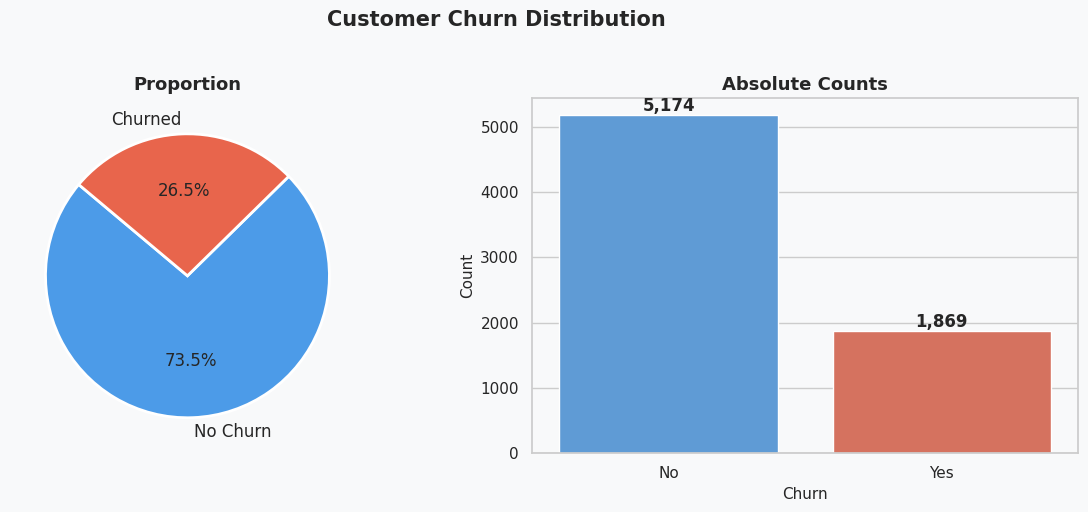


Churn rate: 26.5%
Class imbalance ratio (No:Yes) ≈ 2.8:1


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
fig.suptitle('Customer Churn Distribution', fontsize=15, fontweight='bold', y=1.02)

# Pie chart
counts = df['Churn'].value_counts()
axes[0].pie(
    counts, labels=['No Churn', 'Churned'],
    colors=[COLOR_NO, COLOR_YES], autopct='%1.1f%%',
    startangle=140, wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12}
)
axes[0].set_title('Proportion', fontsize=13, fontweight='bold')

# Count bar
sns.countplot(x='Churn', data=df, palette=PALETTE, ax=axes[1], hue='Churn', legend=False)
axes[1].set_title('Absolute Counts', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Churn', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/01_churn_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nChurn rate: {df["Churn_Binary"].mean()*100:.1f}%')
print(f'Class imbalance ratio (No:Yes) ≈ {counts["No"]/counts["Yes"]:.1f}:1')

## 7. Churn Rate by Contract Type

**Business question:** Does contract length protect against churn?

> This is the **single strongest signal** in the entire dataset.  
> Month-to-month customers churn at roughly 10–15x the rate of two-year contract customers.  
> **Business implication:** Offering incentives to upgrade contract length is the highest-ROI retention strategy.

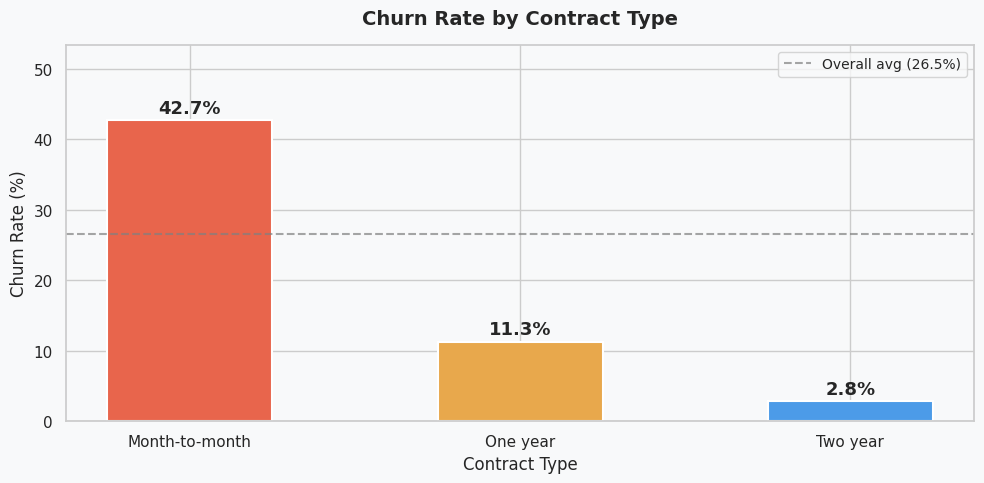

      Contract  Churn_Rate
Month-to-month       42.71
      One year       11.27
      Two year        2.83


In [7]:
churn_by_contract = (
    df.groupby('Contract')['Churn_Binary']
    .mean().mul(100).reset_index()
    .rename(columns={'Churn_Binary': 'Churn_Rate'})
    .sort_values('Churn_Rate', ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(BG)

bar_colors = [COLOR_YES, '#E8A84C', COLOR_NO]  # red → orange → blue
bars = ax.bar(
    churn_by_contract['Contract'], churn_by_contract['Churn_Rate'],
    color=bar_colors, edgecolor='white', linewidth=1.5, width=0.5
)
for bar, val in zip(bars, churn_by_contract['Churn_Rate']):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
        f'{val:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold'
    )

overall_avg = df['Churn_Binary'].mean() * 100
ax.axhline(overall_avg, color='gray', linestyle='--', alpha=0.7, label=f'Overall avg ({overall_avg:.1f}%)')
ax.set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Churn Rate (%)', fontsize=12)
ax.set_xlabel('Contract Type', fontsize=12)
ax.set_ylim(0, churn_by_contract['Churn_Rate'].max() * 1.25)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/02_churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()
print(churn_by_contract.to_string(index=False))

## 8. Tenure Distribution by Churn (KDE Plot)

**Business question:** When do customers most commonly leave?

> Churned customers cluster heavily in the **0–12 month window**, indicating an early-life vulnerability period.  
> Customers who survive past ~24 months are significantly less likely to churn.  
> **Business implication:** Onboarding experience and early-stage engagement programs are critical retention levers.

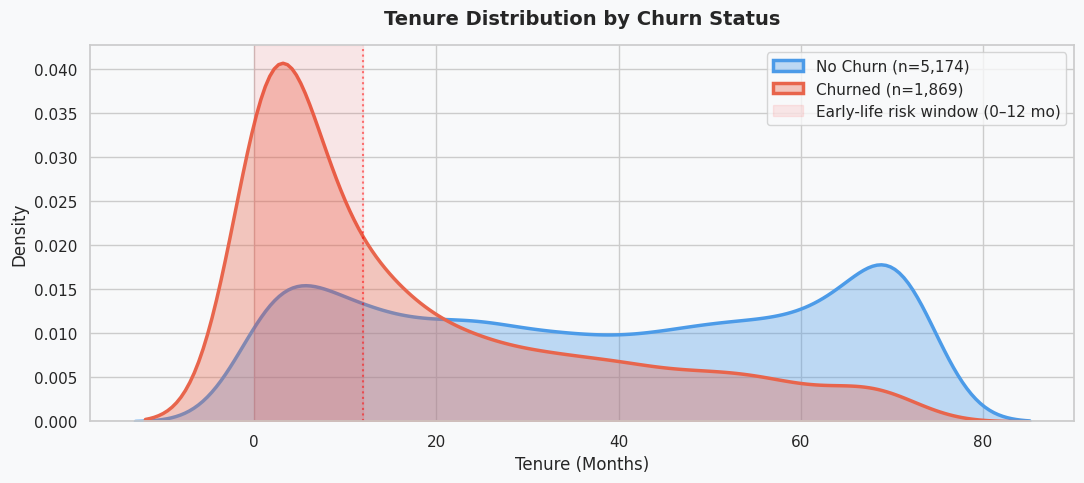

Churn rate in first 12 months : 47.4%
Churn rate after 24 months    : 14.0%


In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(BG)

for churn_val, color, label in [
    ('No', COLOR_NO, 'No Churn'),
    ('Yes', COLOR_YES, 'Churned')
]:
    subset = df[df['Churn'] == churn_val]['tenure']
    sns.kdeplot(subset, ax=ax, color=color, fill=True,
                alpha=0.35, linewidth=2.5, label=f'{label} (n={len(subset):,})')

# Highlight early-life risk window
ax.axvspan(0, 12, alpha=0.08, color='red', label='Early-life risk window (0–12 mo)')
ax.axvline(12, color='red', linestyle=':', alpha=0.5, linewidth=1.5)

ax.set_title('Tenure Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Tenure (Months)', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/03_tenure_kde.png', dpi=150, bbox_inches='tight')
plt.show()

# Quantify the early-life risk
early = df[df['tenure'] <= 12]['Churn_Binary'].mean() * 100
late  = df[df['tenure'] >  24]['Churn_Binary'].mean() * 100
print(f'Churn rate in first 12 months : {early:.1f}%')
print(f'Churn rate after 24 months    : {late:.1f}%')

## 9. Monthly Charges vs. Tenure — Danger Zone Scatter

**Business question:** Is there a profile of customer that combines high price sensitivity with low commitment?

> The top-left quadrant (high charges, low tenure) is the **'Danger Zone'** — customers paying premium prices before they've built loyalty.  
> Churned customers are disproportionately concentrated here.  
> **Business implication:** New high-value customers need proactive outreach within their first 6 months.

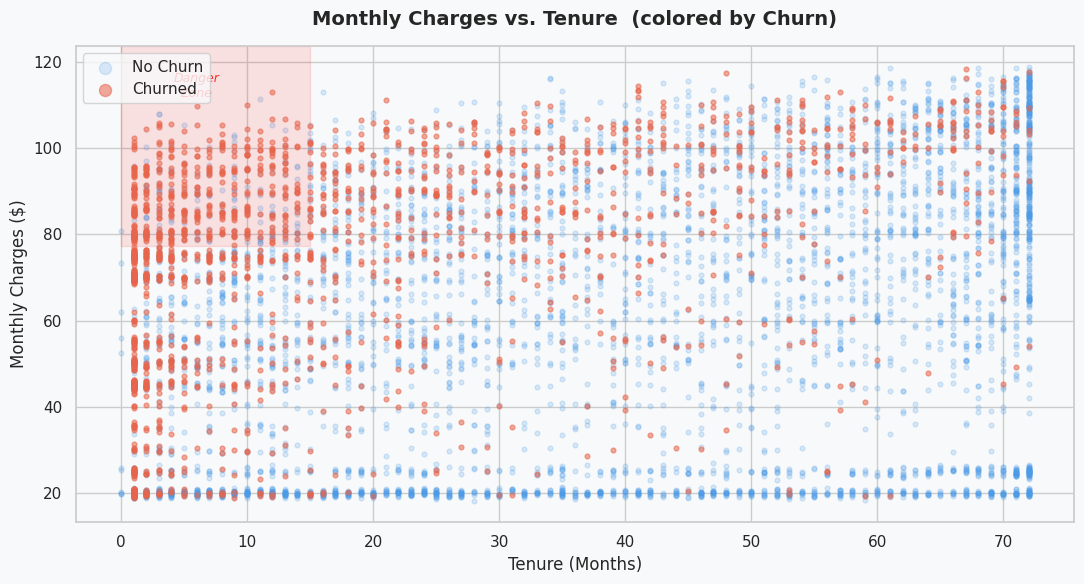

Danger zone customers     : 1,014
Danger zone churn rate    : 66.5%
Overall churn rate        : 26.5%


In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor(BG)

# Plot No Churn first (background), then Churn on top
for churn_val, color, label, alpha, zorder in [
    ('No',  COLOR_NO,  'No Churn', 0.20, 1),
    ('Yes', COLOR_YES, 'Churned',  0.55, 2),
]:
    mask = df['Churn'] == churn_val
    ax.scatter(
        df.loc[mask, 'tenure'], df.loc[mask, 'MonthlyCharges'],
        c=color, alpha=alpha, s=12, label=label, zorder=zorder
    )

# Danger zone annotation
ax.axvspan(0, 15, ymin=0.58, alpha=0.10, color='red')
ax.text(6, 112, 'Danger\nZone', color='red', fontsize=9, alpha=0.8,
        ha='center', style='italic')

ax.set_title('Monthly Charges vs. Tenure  (colored by Churn)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Tenure (Months)', fontsize=12)
ax.set_ylabel('Monthly Charges ($)', fontsize=12)
ax.legend(fontsize=11, markerscale=2.5)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_scatter_charges_tenure.png', dpi=150, bbox_inches='tight')
plt.show()

# Quantify the danger zone
danger = df[(df['tenure'] <= 15) & (df['MonthlyCharges'] >= 70)]
print(f'Danger zone customers     : {len(danger):,}')
print(f'Danger zone churn rate    : {danger["Churn_Binary"].mean()*100:.1f}%')
print(f'Overall churn rate        : {df["Churn_Binary"].mean()*100:.1f}%')

## 10. Churn Rate Across Categorical Features

**Business question:** Which customer attributes and service choices are most associated with churn?

> The highest bar in each subplot is highlighted in red — making the most at-risk group immediately visible.

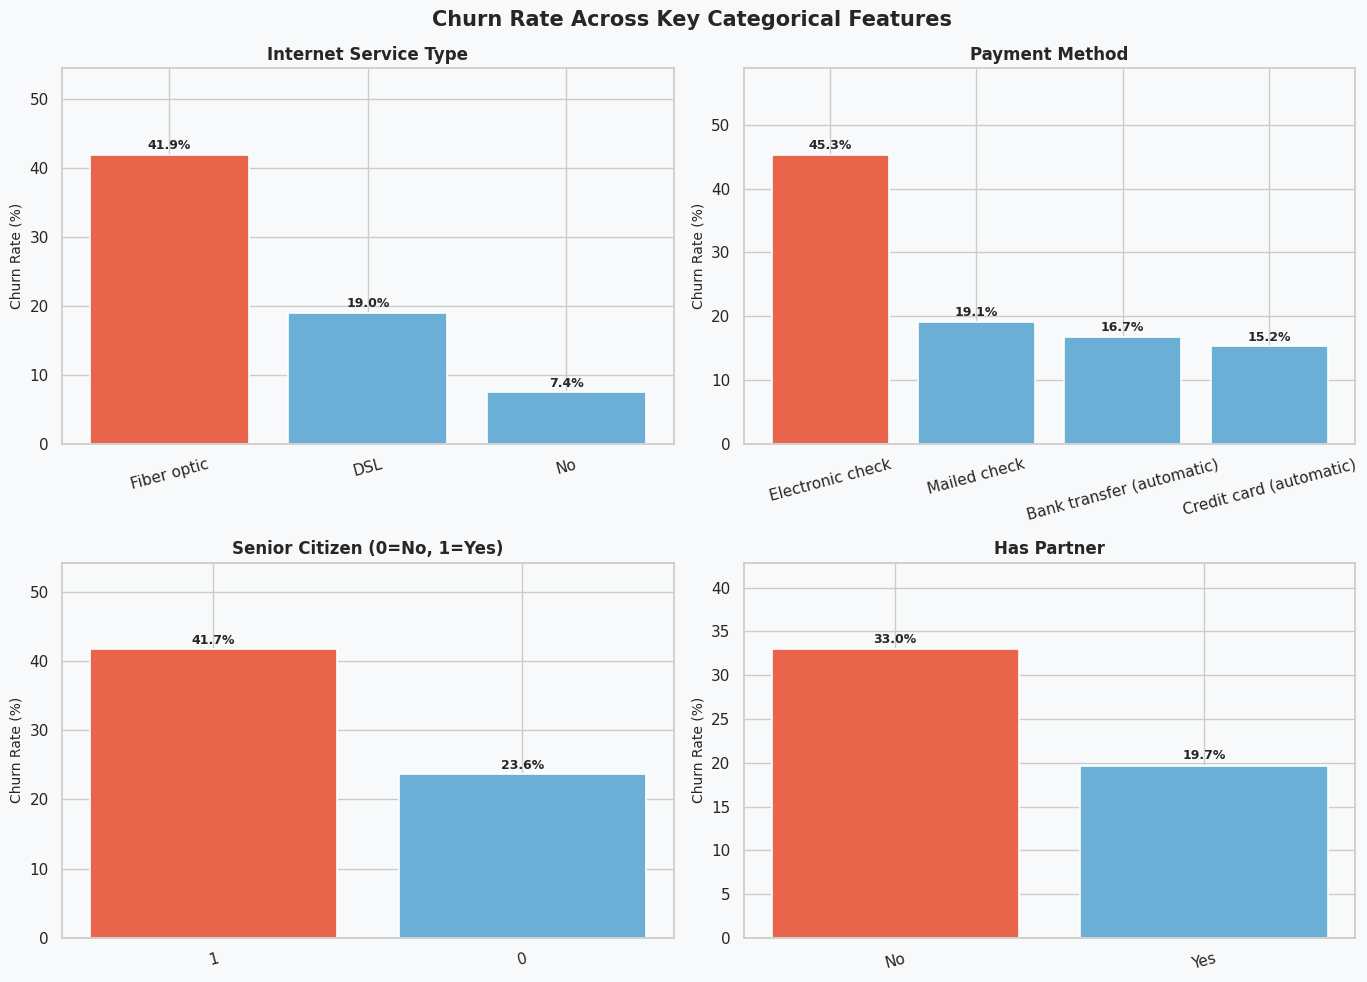

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.patch.set_facecolor(BG)
fig.suptitle('Churn Rate Across Key Categorical Features', fontsize=15, fontweight='bold')

cats = [
    ('InternetService', 'Internet Service Type'),
    ('PaymentMethod',   'Payment Method'),
    ('SeniorCitizen',   'Senior Citizen (0=No, 1=Yes)'),
    ('Partner',         'Has Partner'),
]

for ax, (col, title) in zip(axes.flatten(), cats):
    grp = (
        df.groupby(col)['Churn_Binary']
        .mean().mul(100)
        .sort_values(ascending=False)
    )
    bar_colors = [COLOR_YES if v == grp.max() else '#6BAED6' for v in grp.values]
    bars = ax.bar(grp.index.astype(str), grp.values,
                  color=bar_colors, edgecolor='white', linewidth=1.2)
    for bar, val in zip(bars, grp.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
                f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Churn Rate (%)', fontsize=10)
    ax.set_ylim(0, grp.max() * 1.30)
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_churn_by_categoricals.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Correlation Heatmap

**Business question:** Which numeric features are most correlated with churn? Are any features redundant?

> `TotalCharges` and `tenure` + `MonthlyCharges` will be highly correlated (by construction: Total ≈ Monthly × Tenure).  
> In the modelling phase, we will use `TotalCharges` carefully or drop it to avoid multicollinearity.

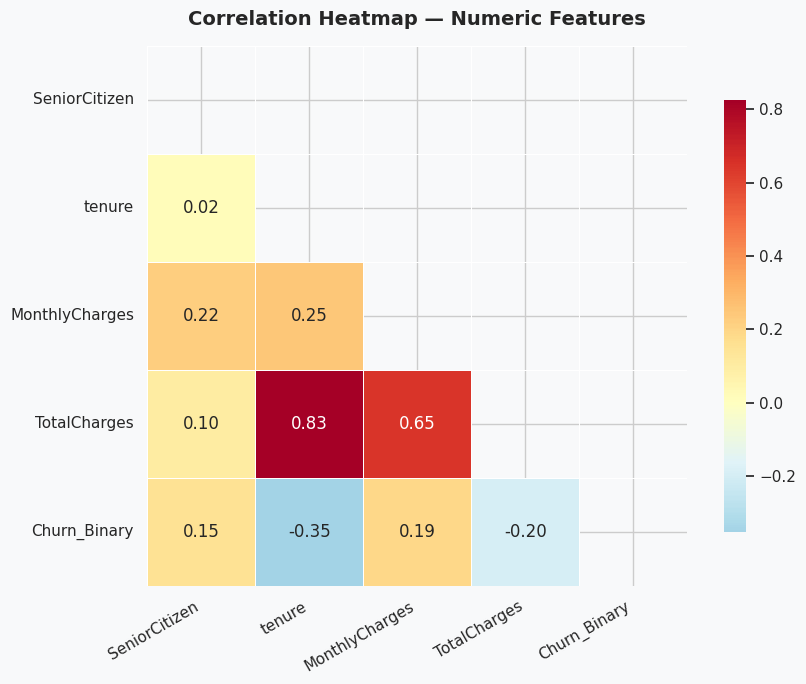

Correlation with Churn_Binary (ranked):
tenure           -0.35
TotalCharges     -0.20
MonthlyCharges    0.19
SeniorCitizen     0.15
Name: Churn_Binary, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor(BG)

num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_Binary']
corr     = df[num_cols].corr()

# Lower triangle only
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu_r',
    center=0, square=True, linewidths=0.5, ax=ax,
    cbar_kws={'shrink': 0.8}, annot_kws={'size': 12}
)
ax.set_title('Correlation Heatmap — Numeric Features', fontsize=14, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/06_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Print churn correlations ranked
print('Correlation with Churn_Binary (ranked):')
print(corr['Churn_Binary'].drop('Churn_Binary').sort_values(key=abs, ascending=False))

## 12. Charge Distributions by Churn — Box Plots

**Business question:** Do churners pay more or less than retained customers?

> Churners tend to have **higher monthly charges** but **lower total charges** — consistent with the danger zone pattern:  
> they're paying premium prices but leaving before accumulating tenure.

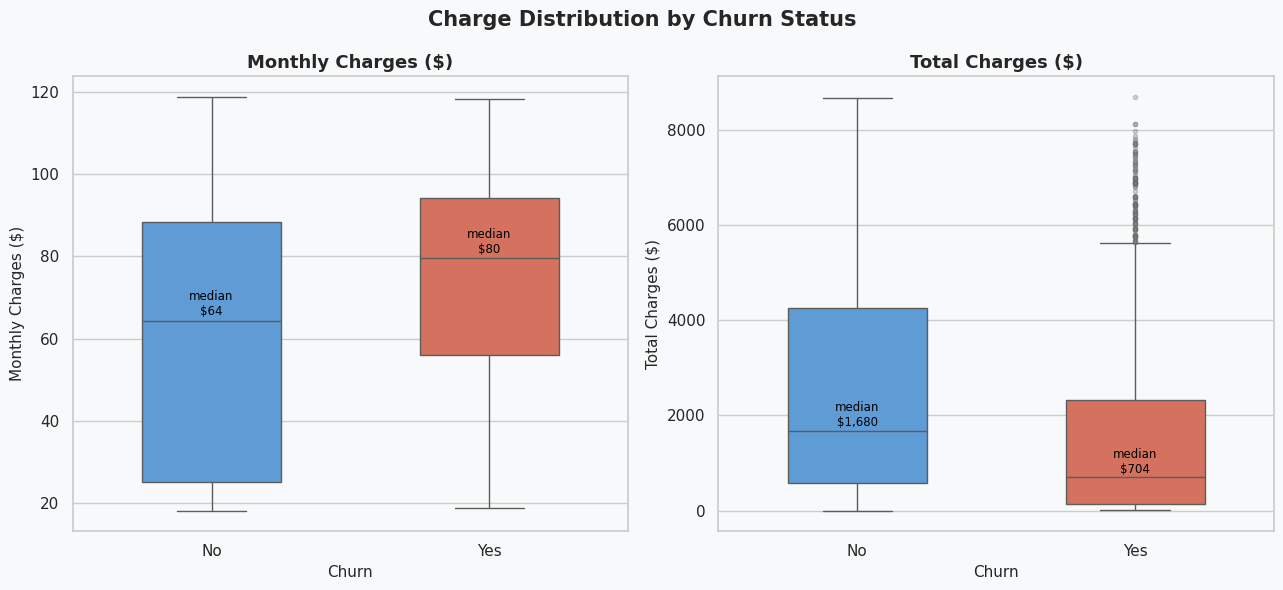

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.patch.set_facecolor(BG)
fig.suptitle('Charge Distribution by Churn Status', fontsize=15, fontweight='bold')

for ax, col, title in zip(
    axes,
    ['MonthlyCharges', 'TotalCharges'],
    ['Monthly Charges ($)', 'Total Charges ($)']
):
    sns.boxplot(
        x='Churn', y=col, data=df, palette=PALETTE, ax=ax,
        hue='Churn', legend=False, width=0.5,
        flierprops=dict(marker='o', markerfacecolor='gray', markersize=3, alpha=0.3)
    )
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Churn', fontsize=11)
    ax.set_ylabel(title, fontsize=11)

    # Annotate medians
    for churn_val in ['No', 'Yes']:
        med = df[df['Churn'] == churn_val][col].median()
        x_pos = 0 if churn_val == 'No' else 1
        ax.text(x_pos, med + ax.get_ylim()[1]*0.01,
                f'median\n${med:,.0f}', ha='center', fontsize=8.5, color='black')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/07_boxplots_charges.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. 📝 Key EDA Findings — Business Summary

These 5 findings will drive every decision in Phase 2 (preprocessing), Phase 3 (segmentation), and Phase 4 (churn prediction).

---

### 🔍 Finding 1 — Class Imbalance Demands Careful Evaluation
The churn rate is approximately **26%**, creating a ~2.8:1 class imbalance.  
A naïve model predicting 'No Churn' for everyone achieves 74% accuracy — which is meaningless.  
**Action:** Use SMOTE for oversampling in Phase 4, and evaluate using AUC-ROC and F1-Score.

---

### 🔍 Finding 2 — Contract Type Is the Dominant Churn Driver
Month-to-month customers churn at **~10–15x the rate** of two-year contract holders.  
This is likely the most actionable variable for the business — a structural retention lever.  
**Action:** `contract_risk_score` will be one of the most important engineered features.

---

### 🔍 Finding 3 — The First 12 Months Are Critical
The KDE plot shows churned customers cluster sharply in the 0–12 month window.  
Customers who survive past ~24 months show dramatically lower churn probability.  
**Action:** `tenure` will be a top predictor. Segment analysis should call out short-tenure clusters.

---

### 🔍 Finding 4 — High Price + Low Tenure = Danger Zone
Customers paying ≥$70/month with ≤15 months of tenure are disproportionately likely to churn.  
This high-charge, low-loyalty combination defines a specific at-risk micro-segment.  
**Action:** The `charge_per_month_ratio` engineered feature directly targets this group.

---

### 🔍 Finding 5 — TotalCharges Has a Hidden Data Quality Bug
`TotalCharges` is stored as object dtype with empty strings instead of nulls for new customers.  
11 rows are affected — all with `tenure = 0`. Handled via numeric coercion and filling with 0.  
**Action:** Document this in README as a real-world data quality example.

---

## ✅ EDA Checklist

- [x] 1.1 Shape, dtypes, nulls, duplicates checked
- [x] 1.2 Churn distribution plotted — class imbalance noted
- [x] 1.3 Churn rate by contract type
- [x] 1.4 Tenure KDE by churn
- [x] 1.5 Monthly charges vs. tenure scatter
- [x] 1.6 Churn rate by payment method, internet service, senior citizen, partner
- [x] 1.7 Correlation heatmap
- [x] 1.8 Box plots: charges by churn
- [x] 1.9 5 key EDA findings written in business language

**Next notebook:** `02_Preprocessing.ipynb` — cleaning, encoding, SMOTE, feature engineering

## 14. Save EDA Snapshot

Save the cleaned (TotalCharges fixed, Churn_Binary added) dataset for use in Notebook 02.

In [13]:
save_path = '../data/processed/telco_eda_snapshot.csv'
df.to_csv(save_path, index=False)
print(f'✅ EDA snapshot saved → {save_path}')
print(f'   Shape: {df.shape}')
print(f'\nFigures saved in: {FIG_DIR}/')
print('  01_churn_distribution.png')
print('  02_churn_by_contract.png')
print('  03_tenure_kde.png')
print('  04_scatter_charges_tenure.png')
print('  05_churn_by_categoricals.png')
print('  06_correlation_heatmap.png')
print('  07_boxplots_charges.png')

✅ EDA snapshot saved → ../data/processed/telco_eda_snapshot.csv
   Shape: (7043, 22)

Figures saved in: ../reports/figures/
  01_churn_distribution.png
  02_churn_by_contract.png
  03_tenure_kde.png
  04_scatter_charges_tenure.png
  05_churn_by_categoricals.png
  06_correlation_heatmap.png
  07_boxplots_charges.png
